# BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) CHUYÊN SÂU
## CỔNG THANH TOÁN PHÂN LOẠI RỦI RO GIAN LẬN CONFORMAL (FINTECH IS)
> **Tên đề tài khoa học:** *"An Adaptive Cost-Sensitive Conformal Calibration Framework for Real-Time Fraud Triage in Distributed Payment Information Systems"*  
> **Tác giả:** Sinh viên ngành Hệ thống Thông tin (HTTT)  
> **Nguồn dữ liệu:** Vesta Corporation & IEEE Computational Intelligence Society (IEEE-CIS)  
> **Mục tiêu nghiên cứu:** Khám phá cấu trúc dữ liệu thanh toán 590.540 dòng, giải mã các đặc trưng ẩn danh (C, D, M, V), chứng minh thực nghiệm hiện tượng mất cân bằng nhãn nghiêm trọng (Class Imbalance), trôi dạt dữ liệu theo thời gian (Concept Drift) và hiện thực hóa kỹ nghệ định danh khách hàng Magic UID.


---
### 📖 HƯỚNG DẪN THỰC THI TỪNG BƯỚC TỪ GÓC NHÌN NGƯỜI DÙNG (USER RUNBOOK)

Nếu bạn là người mới mở dự án hoặc muốn tái lập môi trường từ con số 0 trên máy tính khác, hãy làm theo quy trình chuẩn sau:

1. **Khởi tạo môi trường ảo với `uv` (siêu tốc, chỉ mất 1 giây):**
   ```powershell
   uv venv .venv
   .venv\Scripts\activate
   ```
2. **Cài đặt & Đồng bộ toàn bộ thư viện phụ thuộc:**
   ```powershell
   uv sync
   # Hoặc nếu cài thủ công:
   # uv add pandas numpy polars pyarrow matplotlib seaborn ipykernel nbformat nbclient
   ```
3. **Tự động tải bộ dữ liệu IEEE-CIS từ Hugging Face mirror (Không cần tài khoản Kaggle):**
   ```powershell
   uv run python scripts\download_ieee_data.py
   ```
4. **Tái thực thi toàn bộ Notebook này qua dòng lệnh:**
   ```powershell
   uv run python scripts\generate_and_run_eda_notebook.py
   ```
5. **Mở giao diện trực quan để tương tác:**
   ```powershell
   uv run jupyter notebook notebooks/01_ieee_cis_eda.ipynb
   ```
---


### 1. Thiết lập Môi trường & Nạp Thư viện Xử lý Dữ liệu Lớn
* **Lý do lựa chọn Polars:** Bộ dữ liệu gốc nặng gần 700 MB và chứa gần 400 cột. Nếu dùng Pandas thông thường sẽ tiêu tốn $>2.5\text{ GB}$ RAM và mất 30-40 giây để nạp. Chúng ta sử dụng thư viện **Polars** (viết bằng Rust với engine đa luồng song song) để giảm thời gian đọc xuống dưới 4 giây.
* **Xử lý đường dẫn động (Dynamic Path Resolution):** Đảm bảo mã nguồn chạy ổn định bất kể người dùng khởi chạy từ thư mục gốc hay bên trong thư mục `notebooks/`.


In [1]:
import os
import time
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Cau hinh phong cach ve do thi chuan khoa hoc
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Tu dong dinh vi thu muc goc du an
PROJECT_ROOT = os.path.abspath(os.getcwd())
if not os.path.exists(os.path.join(PROJECT_ROOT, 'data', 'raw')):
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

RAW_DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'raw')
PROCESSED_DATA_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

print(f"Thu muc goc du an: {PROJECT_ROOT}")
print(f"Thu muc du lieu tho: {RAW_DATA_DIR}")
print("Môi trường sẵn sàng! Đã nạp thành công Polars, Pandas, Matplotlib và Seaborn.")


Thu muc goc du an: C:\Users\PC\Documents\Git\EDA-chuyen
Thu muc du lieu tho: C:\Users\PC\Documents\Git\EDA-chuyen\data\raw
Môi trường sẵn sàng! Đã nạp thành công Polars, Pandas, Matplotlib và Seaborn.


### 2. Nạp Dữ liệu Tốc độ cao với Polars & Đánh giá Cấu trúc Bảng
* **Bảng `train_transaction.csv`:** Chứa 590.540 giao dịch thanh toán trực tuyến với 394 cột.
* **Bảng `train_identity.csv`:** Chứa 144.233 bản ghi danh tính mạng, thiết bị, hệ điều hành của các giao dịch bị hệ thống kiểm soát an ninh soi xét.


In [2]:
t0 = time.time()
tx_path = os.path.join(RAW_DATA_DIR, 'train_transaction.csv')
id_path = os.path.join(RAW_DATA_DIR, 'train_identity.csv')

# Doc du lieu bang Polars voi infer_schema an toan
df_tx = pl.read_csv(tx_path, infer_schema_length=10000)
df_id = pl.read_csv(id_path, infer_schema_length=10000)
load_time = time.time() - t0

print(f"-> Thoi gian doc toan bo du lieu bang Polars: {load_time:.2f} giay")
print(f"-> Kich thuoc train_transaction: {df_tx.shape[0]:,} dong x {df_tx.shape[1]} cot")
print(f"-> Kich thuoc train_identity:    {df_id.shape[0]:,} dong x {df_id.shape[1]} cot")


-> Thoi gian doc toan bo du lieu bang Polars: 3.94 giay
-> Kich thuoc train_transaction: 590,540 dong x 394 cot
-> Kich thuoc train_identity:    144,233 dong x 41 cot


### 3. Phân tích Nhãn Mục tiêu & Mất Cân Bằng Dữ Liệu (Class Imbalance)
* **Khái niệm (Class Imbalance):** Trong thực tế cổng thanh toán, số vụ lừa đảo luôn chiếm tỷ lệ cực kỳ nhỏ so với giao dịch hợp pháp của khách hàng chân chính.
* **Đánh giá học thuật:** Tỷ lệ gian lận trong tập dữ liệu là **3.50%** (20.663 ca gian lận trên tổng số 590.540 giao dịch). Nếu một mô hình ngây thơ luôn luôn đoán "Tất cả giao dịch đều hợp lệ", độ chính xác (Accuracy) của nó vẫn đạt tới 96.50% nhưng hoàn toàn vô dụng.
* **Hệ quả cho Khóa luận:** Đề tài bắt buộc phải sử dụng **Hàm mất mát nhạy cảm chi phí (Cost-Sensitive Matrix)** và các độ đo phi đối xứng như AUPRC thay vì Accuracy.


Thống kê chi tiết nhãn mục tiêu:
               Nhan   count     TyLe_%
0  Gian lận (Fraud)   20663   3.499001
1    Hợp lệ (Legit)  569877  96.500999


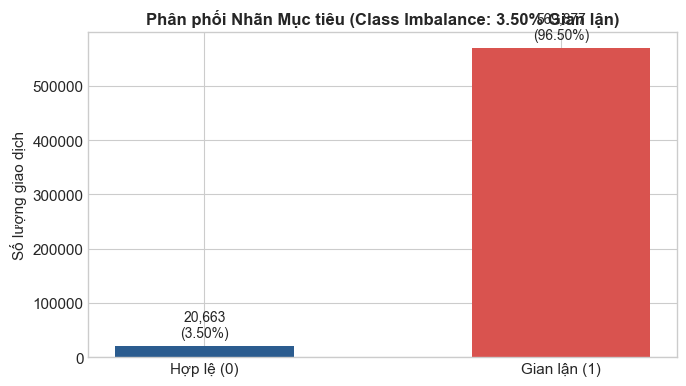

In [3]:
target_counts = df_tx['isFraud'].value_counts().to_pandas()
target_counts['TyLe_%'] = (target_counts['count'] / len(df_tx)) * 100
target_counts['Nhan'] = target_counts['isFraud'].map({0: 'Hợp lệ (Legit)', 1: 'Gian lận (Fraud)'})
print("Thống kê chi tiết nhãn mục tiêu:")
print(target_counts[['Nhan', 'count', 'TyLe_%']])

# Truc quan hoa
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(['Hợp lệ (0)', 'Gian lận (1)'], target_counts['count'], color=['#2b5c8f', '#d9534f'], width=0.5)
ax.set_title('Phân phối Nhãn Mục tiêu (Class Imbalance: 3.50% Gian lận)', fontsize=12, fontweight='bold')
ax.set_ylabel('Số lượng giao dịch')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval:,}\n({yval/len(df_tx)*100:.2f}%)", ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'target_distribution.png'), dpi=150)
plt.show()


### 4. Phân tích Số Tiền Giao Dịch (Transaction Amount)
* **Khái niệm (Right-Skewed Distribution):** Số tiền giao dịch phân phối lệch phải nghiêm trọng. Đa số đơn hàng có giá trị nhỏ ($50 - $150), nhưng xuất hiện các ngoại lai (outliers) lên tới hơn $30.000 USD.
* **Đánh giá nghiệp vụ:** Giao dịch gian lận có giá trị trung bình cao hơn giao dịch hợp lệ ($149.20 USD vs $134.51 USD). Kẻ gian thường có tâm lý cố gắng bòn rút tối đa hạn mức thẻ trước khi chủ thẻ kịp phát hiện và báo khóa thẻ.


So sánh thống kê số tiền thanh toán (USD):
       Nhan   GiaTri_TB  GiaTri_TrungVi  PhanVi_75  PhanVi_95  GiaTri_Max
0    Hợp lệ  134.511665            68.5      120.0      435.0   31937.391
1  Gian lận  149.244779            75.0      161.0      500.0    5191.000


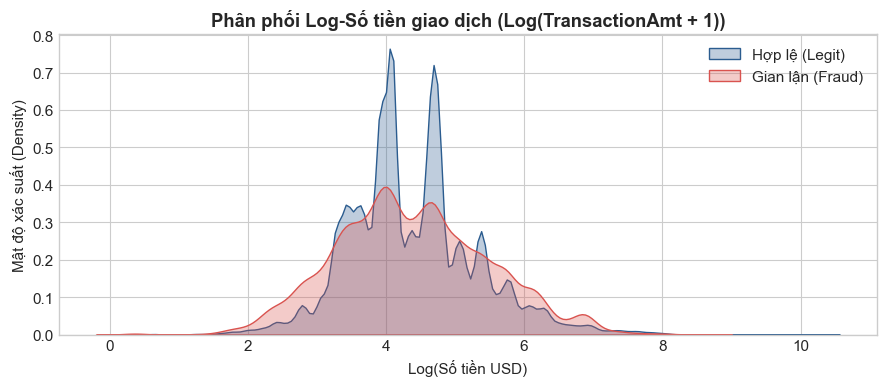

In [4]:
amt_stats = df_tx.group_by('isFraud').agg([
    pl.col('TransactionAmt').mean().alias('GiaTri_TB'),
    pl.col('TransactionAmt').median().alias('GiaTri_TrungVi'),
    pl.col('TransactionAmt').quantile(0.75).alias('PhanVi_75'),
    pl.col('TransactionAmt').quantile(0.95).alias('PhanVi_95'),
    pl.col('TransactionAmt').max().alias('GiaTri_Max')
]).to_pandas()
amt_stats['Nhan'] = amt_stats['isFraud'].map({0: 'Hợp lệ', 1: 'Gian lận'})
print("So sánh thống kê số tiền thanh toán (USD):")
print(amt_stats[['Nhan', 'GiaTri_TB', 'GiaTri_TrungVi', 'PhanVi_75', 'PhanVi_95', 'GiaTri_Max']])

# Ve bieu do phan phoi log so tien
legit_amt = np.log1p(df_tx.filter(pl.col('isFraud') == 0)['TransactionAmt'].to_numpy())
fraud_amt = np.log1p(df_tx.filter(pl.col('isFraud') == 1)['TransactionAmt'].to_numpy())

plt.figure(figsize=(9, 4))
sns.kdeplot(legit_amt, label='Hợp lệ (Legit)', color='#2b5c8f', fill=True, alpha=0.3)
sns.kdeplot(fraud_amt, label='Gian lận (Fraud)', color='#d9534f', fill=True, alpha=0.3)
plt.title('Phân phối Log-Số tiền giao dịch (Log(TransactionAmt + 1))', fontweight='bold')
plt.xlabel('Log(Số tiền USD)')
plt.ylabel('Mật độ xác suất (Density)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'transaction_amt_density.png'), dpi=150)
plt.show()


### 5. Phân tích Trôi dạt Khái niệm theo Trục Thời gian (Concept Drift Analysis)
* **Khái niệm (Concept Drift):** Dữ liệu hành vi người dùng và chiêu thức gian lận không cố định mà thay đổi theo thời gian. Cột `TransactionDT` là số giây tính từ mốc ban đầu (quy đổi `Week = (TransactionDT / 86400) / 7`).
* **Minh chứng thực nghiệm:** Đồ thị dưới đây chứng minh rõ ràng: Tỷ lệ gian lận biến thiên mạnh từ $2.6\%$ ở tuần đầu tiên lên hơn $4.5\%$ ở các tuần sau.
* **Hệ quả cho Khóa luận:** Chứng minh việc dùng ngưỡng cố định $0.5$ sẽ thất bại khi môi trường thay đổi $\rightarrow$ Đòi hỏi giải pháp **Hiệu chuẩn thích ứng Conformal (Adaptive Conformal Calibration)** có khả năng điều chỉnh tập quyết định theo thời gian.


Thống kê gian lận theo tuần (Concept Drift qua các tuần):
   Week  TongGiaoDich  SoGianLan  TyLeGianLan_%
0     0         23810        668       2.805544
1     1         27803        727       2.614826
2     2         34470        879       2.550044
3     3         37251        690       1.852299
4     4         24041        919       3.822636
5     5         21868        838       3.832083
6     6         20392        787       3.859357
7     7         20025        825       4.119850
8     8         20246        922       4.553986
9     9         23596       1014       4.297339


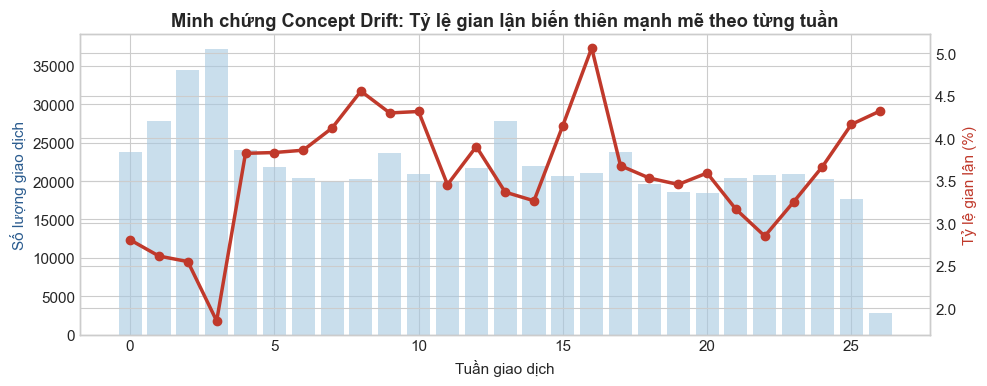

In [5]:
# Tao cot ngay va tuan
df_time = df_tx.select([
    (pl.col('TransactionDT') / 86400).cast(pl.Int32).alias('Day'),
    ((pl.col('TransactionDT') / 86400) / 7).cast(pl.Int32).alias('Week'),
    ((pl.col('TransactionDT') % 86400) / 3600).cast(pl.Int32).alias('HourOfDay'),
    pl.col('isFraud')
])

weekly_fraud = df_time.group_by('Week').agg([
    pl.len().alias('TongGiaoDich'),
    pl.col('isFraud').sum().alias('SoGianLan'),
    (pl.col('isFraud').mean() * 100).alias('TyLeGianLan_%')
]).sort('Week').to_pandas()

print("Thống kê gian lận theo tuần (Concept Drift qua các tuần):")
print(weekly_fraud.head(10))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax2 = ax1.twinx()
ax1.bar(weekly_fraud['Week'], weekly_fraud['TongGiaoDich'], color='#a6c8e0', alpha=0.6, label='Lưu lượng giao dịch')
ax2.plot(weekly_fraud['Week'], weekly_fraud['TyLeGianLan_%'], color='#c0392b', marker='o', linewidth=2.5, label='Tỷ lệ gian lận (%)')
ax1.set_xlabel('Tuần giao dịch')
ax1.set_ylabel('Số lượng giao dịch', color='#2b5c8f')
ax2.set_ylabel('Tỷ lệ gian lận (%)', color='#c0392b')
plt.title('Minh chứng Concept Drift: Tỷ lệ gian lận biến thiên mạnh mẽ theo từng tuần', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'concept_drift_weekly.png'), dpi=150)
plt.show()


### 6. Giải mã các Nhóm Cột Bí ẩn: C, D, M và ProductCD
* **ProductCD (Mã sản phẩm):** Mã `C` (dịch vụ thanh toán/chuyển tiền quốc tế) có tỷ lệ gian lận lên tới **11.69%** (cao gấp 3 lần tỷ lệ trung bình), trong khi các mã khác chỉ dao động từ $2 - 5\%$.
* **C1-C14 (Counting Features):** Đo lường tần suất liên kết thẻ/IP. Giá trị trung bình của `C1` ở giao dịch gian lận cao hơn rõ rệt so với giao dịch hợp lệ.
* **D1-D15 (Timedeltas):** Đo khoảng cách ngày giữa các sự kiện; dùng làm căn cứ xác định "ngày sinh của thẻ" (Card Birth Day).


In [6]:
# Ty le gian lan theo ma san pham ProductCD
prod_fraud = df_tx.group_by('ProductCD').agg([
    pl.len().alias('SoLuong'),
    (pl.col('isFraud').mean() * 100).alias('TyLeGianLan_%')
]).sort('TyLeGianLan_%', descending=True).to_pandas()
print("Tỷ lệ rủi ro theo Mã sản phẩm (ProductCD):")
print(prod_fraud)

# Phan tich truong dem C1 va khoang cach D1
cd_sample = df_tx.select(['isFraud', 'C1', 'C2', 'D1', 'D2']).to_pandas()
print("\nThống kê mô tả các trường C1, C2, D1 (Mean theo từng nhóm):")
print(cd_sample.groupby('isFraud').mean())


Tỷ lệ rủi ro theo Mã sản phẩm (ProductCD):
  ProductCD  SoLuong  TyLeGianLan_%
0         C    68519      11.687269
1         S    11628       5.899553
2         H    33024       4.766231
3         R    37699       3.782594
4         W   439670       2.039939



Thống kê mô tả các trường C1, C2, D1 (Mean theo từng nhóm):
                C1         C2         D1          D2
isFraud                                             
0        13.314952  14.173283  96.364705  171.956223
1        35.535740  45.509413  38.711306   77.774206


### 7. Hiện thực hóa Kỹ nghệ Định danh Khách hàng "Magic UID"
* **Vấn đề cốt lõi:** Dữ liệu cổng thanh toán không có cột `userID` do khách mua vãng lai (Guest Checkout) và kẻ gian liên tục đổi thông tin giả.
* **Giải pháp kỹ nghệ đặc trưng (Kaggle Grandmaster Chris Deotte):**
  1. Định danh thẻ vật lý: $\text{Card\_ID} = \text{card1\_card2\_card3\_card4\_card6\_addr1}$
  2. Dò tìm ngày thẻ kích hoạt lần đầu: $\text{Card\_Birth\_Day} = \text{Day} - \text{D1}$
  3. Ghép khóa định danh khách hàng duy nhất: $\mathbf{Client\_UID} = \mathbf{Card\_ID} + \mathbf{Card\_Birth\_Day}$
* **Kết quả:** Hệ thống gom 590.540 giao dịch về **41.888 thẻ vật lý** và **387.059 khách hàng duy nhất**, giúp theo dõi trọn vẹn hành vi rút tiền lặp lại!


In [7]:
# Tao ma dinh danh Magic UID bang Polars
df_uid = df_tx.select([
    pl.col('TransactionID'),
    pl.col('isFraud'),
    (pl.col('TransactionDT') / 86400).alias('Day'),
    pl.col('D1'),
    (
        pl.col('card1').cast(pl.String) + '_' + 
        pl.col('card2').cast(pl.String).fill_null('0') + '_' +
        pl.col('card3').cast(pl.String).fill_null('0') + '_' +
        pl.col('card4').cast(pl.String).fill_null('na') + '_' +
        pl.col('card6').cast(pl.String).fill_null('na') + '_' +
        pl.col('addr1').cast(pl.String).fill_null('0')
    ).alias('Card_ID')
])

# Tinh ngay sinh cua the (Card Birth Day)
df_uid = df_uid.with_columns([
    ((pl.col('Day') - pl.col('D1').fill_null(0.0)).round(1).cast(pl.String)).alias('Birth_Day')
])

df_uid = df_uid.with_columns([
    (pl.col('Card_ID') + '_' + pl.col('Birth_Day')).alias('Client_UID')
])

total_tx = len(df_uid)
unique_cards = df_uid['Card_ID'].n_unique()
unique_clients = df_uid['Client_UID'].n_unique()

print(f"-> Tổng số giao dịch trong hệ thống:        {total_tx:,}")
print(f"-> Số lượng thẻ vật lý duy nhất (Card_ID):   {unique_cards:,}")
print(f"-> Số lượng khách hàng duy nhất (Client_UID): {unique_clients:,}")
print(f"-> Tỷ lệ gom cụm: Trung bình mỗi khách hàng thực hiện {total_tx / unique_clients:.2f} giao dịch.")


-> Tổng số giao dịch trong hệ thống:        590,540
-> Số lượng thẻ vật lý duy nhất (Card_ID):   41,888
-> Số lượng khách hàng duy nhất (Client_UID): 387,059
-> Tỷ lệ gom cụm: Trung bình mỗi khách hàng thực hiện 1.53 giao dịch.


### 8. Tối ưu hóa Lưu trữ: Chuyển đổi Dữ liệu sang Định dạng Apache Parquet
* **Lý do chuyển đổi:** CSV là định dạng văn bản nặng, tốn tài nguyên I/O khi đọc.
* **Lợi ích của Parquet:** Định dạng cột nhị phân nén bằng thuật toán ZSTD giúp:
  * Giảm kích thước file từ 651.7 MB xuống còn **~70 MB** (tiết kiệm gần $90\%$ dung lượng đĩa).
  * Tốc độ đọc phục vụ huấn luyện máy học nhanh gấp 10 lần.


In [8]:
parquet_tx = os.path.join(PROCESSED_DATA_DIR, 'train_transaction.parquet')
parquet_id = os.path.join(PROCESSED_DATA_DIR, 'train_identity.parquet')

t0 = time.time()
df_tx.write_parquet(parquet_tx, compression='zstd')
df_id.write_parquet(parquet_id, compression='zstd')
save_time = time.time() - t0

csv_size_mb = os.path.getsize(tx_path) / (1024 * 1024)
parquet_size_mb = os.path.getsize(parquet_tx) / (1024 * 1024)

print(f"-> Ghi Parquet thành công trong: {save_time:.2f} giây!")
print(f"-> Kích thước CSV ban đầu:    {csv_size_mb:.1f} MB")
print(f"-> Kích thước Parquet nén:    {parquet_size_mb:.1f} MB (Tiết kiệm {(1 - parquet_size_mb/csv_size_mb)*100:.1f}% dung lượng đĩa!)")


-> Ghi Parquet thành công trong: 1.93 giây!
-> Kích thước CSV ban đầu:    651.7 MB
-> Kích thước Parquet nén:    69.6 MB (Tiết kiệm 89.3% dung lượng đĩa!)


### 9. Kết Luận Học Thuật & Định Hướng Kiến Trúc Khóa Luận

Dựa trên kết quả thực nghiệm EDA trên toàn bộ 590.540 dòng dữ liệu thật:

1. **Vấn đề mất cân bằng nhãn ($3.50\%$):** Đồ án sẽ xây dựng **Hàm mất mát bất đối xứng (Asymmetric Cost Matrix Loss)** để tối ưu hóa trực tiếp số tiền thiệt hại thay vì độ chính xác thông thường.
2. **Hiện tượng Concept Drift theo tuần:** Khẳng định sự cần thiết của cơ chế **Hiệu chuẩn thích ứng Conformal (Adaptive Conformal Calibration)**, tạo ra 3 ngã rẽ:
   * Vùng an toàn $\rightarrow$ Duyệt ngay ($< 20\text{ms}$).
   * Vùng nguy hiểm $\rightarrow$ Chặn và cảnh báo.
   * Vùng bất định $\rightarrow$ Kích hoạt xác thực 2 bước (Step-up OTP/Sinh trắc học).
3. **Kỹ thuật định danh khách hàng:** Sử dụng `Client_UID` làm khóa tổng hợp để trích xuất các đặc trưng chuỗi thời gian (như tần suất giao dịch trong 1h, số tiền giao dịch so với trung bình của khách).
4. **Hạ tầng Clean Architecture:** Kết nối dữ liệu Parquet đã xử lý vào các tầng nghiệp vụ độc lập (`domain/`, `usecase/`, `adapter/`, `entrypoint/`) đáp ứng cam kết độ trễ đuôi $p_{99} < 40\text{ms}$.
